OpenMC seems to run into the same concavity/convexity issue as described in the MCNP6 user guide w.r.t cell 1, which is composed of two perpendicular cylinders. Thankfully, the same fix (use surface 5, a disambiguation surface, to make two independent cells, then union them) works fine. 

In [1]:
import openmc

# Surface definitions
s1 = openmc.XCylinder(z0=6,r=3)
s2 = openmc.XPlane(x0=0)
s3 = openmc.ZCylinder(x0=6, r=3)
s4 = openmc.ZPlane(z0=0)
s5 = openmc.Plane(a=-1,c=1)

                        # center, height, radius, axis, upper/lower fillet radii
halfspace1 = openmc.model.RightCircularCylinder((0,0,-0.5),1,2,'z',0.0,0.0)
halfspace1 = halfspace1.rotate((0,45,0))
halfspace1 = halfspace1.translate((5,0,6))
c2 = openmc.Cell(cell_id=2,fill=None,region=-halfspace1)

In [2]:
# Cell definitions
c1 = openmc.Cell(fill=None,region=(+s2 & -s1 &+s5) | (-s3 & +s4 & -s5) & ~c2.region)
c3 = openmc.Cell(fill=None,region=(-s2 | +s1  |- s5) & (+s3 | -s4 | + s5))
geometry=openmc.Geometry([c1, c2, c3])
#print(geometry.get_all_surfaces())
geometry.export_to_xml()

In [3]:
material=openmc.Materials()
material.export_to_xml()

setting = openmc.Settings()
setting.export_to_xml()

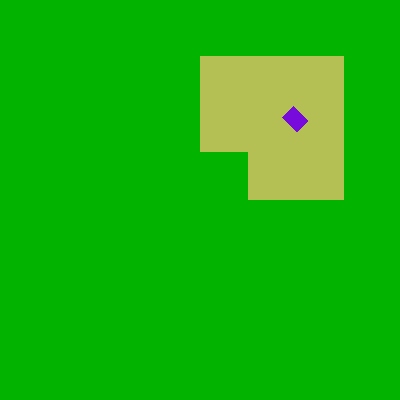

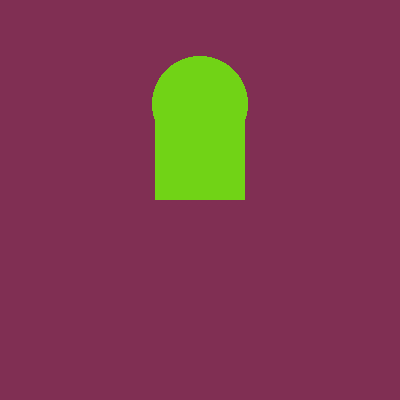

In [4]:
w = 25
plots = openmc.Plots()

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'

plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (5.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'

plots.append(plot)
openmc.plot_inline(plots)

# in this case, may need to use opennmc-plotter to get a better picture